# 21 — Parallel SWMM scenario runs

This notebook demonstrates how to run independent SWMMX scenarios in parallel. It is designed for scenario families such as different rainfall events, LID strategies, conduit diameters, node elevations, roughness values, or combined design alternatives.

The safest rule is:

> **One scenario = one fresh model = one separate process.**

Do not share the same `m` object between workers. Each worker should build or open its own model, apply scenario edits, run SWMM, and write its own outputs.


## Why this notebook uses subprocess workers

Python notebooks on Windows often cannot use `ProcessPoolExecutor` directly with functions defined inside notebook cells, because worker processes must import the function from a real Python module. To keep the workflow reliable in Jupyter, Spyder, Windows, Linux, and macOS, this notebook writes a small worker script to disk and runs it with `subprocess`.

That gives true process-level parallelism while keeping the notebook readable.

This does **not** require a SWMMX package change. It is an example workflow, so no version bump to `0.0.43` is needed.


In [1]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import json
import os
import re
import subprocess
import sys
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

_here = Path.cwd().resolve()
for _candidate in (_here / "src", _here.parent / "src"):
    if (_candidate / "swmmx").exists() and str(_candidate) not in sys.path:
        sys.path.insert(0, str(_candidate))
        break

import swmmx
from swmmx import swmm

print(f"Using swmmx {swmmx.__version__} from {Path(swmmx.__file__).resolve()}")

OUTPUT_DIR = Path("output/parallel_scenario_lab")
SPECS_DIR = OUTPUT_DIR / "specs"
RESULTS_DIR = OUTPUT_DIR / "results"
for folder in (OUTPUT_DIR, SPECS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True


Using swmmx 0.0.42 from C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\src\swmmx\__init__.py


## Scenario specifications

Each scenario is just a dictionary. In a real project, these could come from a CSV/Excel design table. Here we mix several common changes: rainfall return period, climate factor, conduit diameter multiplier, node invert shift, roughness multiplier, and optional LID strategy.


In [2]:
SCENARIOS = [
    {"name": "Baseline — 2-year storm", "return_period": "2-year", "rain_depth_mm": 45.0, "climate_factor": 1.00, "diameter_multiplier": 1.00, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": None},
    {"name": "30-year storm", "return_period": "30-year", "rain_depth_mm": 85.0, "climate_factor": 1.00, "diameter_multiplier": 1.00, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": None},
    {"name": "100-year storm", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.00, "diameter_multiplier": 1.00, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": None},
    {"name": "100-year storm — climate +20%", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.20, "diameter_multiplier": 1.00, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": None},
    {"name": "100-year climate +20% — conduits +25%", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.20, "diameter_multiplier": 1.25, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": None},
    {"name": "100-year climate +20% — lower inverts 0.3 m", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.20, "diameter_multiplier": 1.00, "invert_shift_m": -0.30, "roughness_multiplier": 1.00, "lid": None},
    {"name": "100-year climate +20% — rough conduits", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.20, "diameter_multiplier": 1.00, "invert_shift_m": 0.00, "roughness_multiplier": 1.35, "lid": None},
    {"name": "100-year climate +20% — bio-retention 10%", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.20, "diameter_multiplier": 1.00, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": {"control": "BR", "area_percent": 10.0}},
    {"name": "100-year climate +20% — conduits +25% and BR 10%", "return_period": "100-year", "rain_depth_mm": 115.0, "climate_factor": 1.20, "diameter_multiplier": 1.25, "invert_shift_m": 0.00, "roughness_multiplier": 1.00, "lid": {"control": "BR", "area_percent": 10.0}},
]

pd.DataFrame(SCENARIOS)


,name,return_period,rain_depth_mm,climate_factor,diameter_multiplier,invert_shift_m,roughness_multiplier,lid
0,Baseline — 2-year storm,2-year,45.0,1.0,1.00,0.0,1.00,None
1,30-year storm,30-year,85.0,1.0,1.00,0.0,1.00,None
2,100-year storm,100-year,115.0,1.0,1.00,0.0,1.00,None
3,100-year storm — climate +20%,100-year,115.0,1.2,1.00,0.0,1.00,None
4,100-year climate +20% — conduits +25%,100-year,115.0,1.2,1.25,0.0,1.00,None
5,100-year climate +20% — lower inverts 0.3 m,100-year,115.0,1.2,1.00,-0.3,1.00,None
6,100-year climate +20% — rough conduits,100-year,115.0,1.2,1.00,0.0,1.35,None
7,100-year climate +20% — bio-retention 10%,100-year,115.0,1.2,1.00,0.0,1.00,"{'control': 'BR', 'area_percent': 10.0}"
8,100-year climate +20% — conduits +25% and BR 10%,100-year,115.0,1.2,1.25,0.0,1.00,"{'control': 'BR', 'area_percent': 10.0}"


## Worker script

The worker script is the function body for a single scenario. It builds a fresh model, applies the scenario edits, runs SWMM, and writes one JSON metrics file, one CSV total-runoff hydrograph, and one scenario `.inp` file.


In [3]:
WORKER_SCRIPT = OUTPUT_DIR / "parallel_swmmx_worker.py"
worker_source = '\nfrom __future__ import annotations\n\nfrom pathlib import Path\nimport json\nimport re\nimport sys\nimport traceback\n\nimport pandas as pd\n\nREPO_SRC = Path(__file__).resolve().parents[2] / "src"\nif REPO_SRC.exists() and str(REPO_SRC) not in sys.path:\n    sys.path.insert(0, str(REPO_SRC))\n\nfrom swmmx import swmm\n\nSTART = pd.Timestamp("2000-01-01 00:00")\nDURATION_HOURS = 6\nSTEP_MINUTES = 5\nSUBCATCHMENTS = [f"S{i}" for i in range(1, 6)]\n\n\ndef slugify(text):\n    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")\n\n\ndef design_hyetograph(total_depth_mm, *, start=START, duration_hours=DURATION_HOURS, step_minutes=STEP_MINUTES):\n    periods = int(duration_hours * 60 / step_minutes) + 1\n    times = pd.date_range(start, periods=periods, freq=f"{step_minutes}min")\n    weights = []\n    for i in range(periods):\n        fraction = i / (periods - 1)\n        if fraction < 0.18:\n            weight = 0.15\n        elif fraction < 0.35:\n            weight = 0.75\n        elif fraction < 0.50:\n            weight = 1.80\n        elif fraction < 0.62:\n            weight = 3.20\n        elif fraction < 0.75:\n            weight = 1.25\n        elif fraction < 0.90:\n            weight = 0.45\n        else:\n            weight = 0.12\n        weights.append(weight)\n    weights = pd.Series(weights, index=times, dtype=float)\n    interval_depth_mm = weights / weights.sum() * total_depth_mm\n    intensity_mm_per_hr = interval_depth_mm / (step_minutes / 60)\n    return intensity_mm_per_hr.rename("rainfall_intensity_mm_hr")\n\n\ndef swmm_time_series_rows(intensity):\n    return [(time.strftime("%m/%d/%Y %H:%M"), float(value)) for time, value in intensity.items()]\n\n\ndef build_model(spec):\n    m = swmm(new="SI")\n    end = START + pd.Timedelta(hours=DURATION_HOURS)\n    options = {\n        "FLOW_UNITS": "CMS",\n        "INFILTRATION": "HORTON",\n        "FLOW_ROUTING": "KINWAVE",\n        "START_DATE": START.strftime("%m/%d/%Y"),\n        "START_TIME": START.strftime("%H:%M:%S"),\n        "END_DATE": end.strftime("%m/%d/%Y"),\n        "END_TIME": end.strftime("%H:%M:%S"),\n        "REPORT_START_DATE": START.strftime("%m/%d/%Y"),\n        "REPORT_START_TIME": START.strftime("%H:%M:%S"),\n        "REPORT_STEP": "00:05:00",\n        "WET_STEP": "00:05:00",\n        "DRY_STEP": "00:05:00",\n        "ROUTING_STEP": "00:01:00",\n    }\n    for key, value in options.items():\n        m.options[key] = value\n\n    rainfall_depth = float(spec["rain_depth_mm"]) * float(spec.get("climate_factor", 1.0))\n    rainfall = design_hyetograph(rainfall_depth)\n    m.add.time.time_series("ScenarioRain", data=swmm_time_series_rows(rainfall))\n    m.add.hydrology.rain_gage("RG1", format="INTENSITY", interval="00:05", source_type="TIMESERIES", time_series="ScenarioRain", x=-40, y=120)\n\n    invert_shift = float(spec.get("invert_shift_m", 0.0))\n    for i in range(1, 6):\n        m.add.node.junction(f"J{i}", x=i * 100, y=0, invert_elevation=10 - i * 0.20 + invert_shift, max_depth=4.0)\n    m.add.node.outfall("OUT1", x=650, y=0, invert_elevation=8.0 + invert_shift, type="FREE")\n\n    diameter = 1.20 * float(spec.get("diameter_multiplier", 1.0))\n    roughness = 0.013 * float(spec.get("roughness_multiplier", 1.0))\n    for i in range(1, 5):\n        m.add.link.conduit(f"C{i}", from_node=f"J{i}", to_node=f"J{i+1}", roughness=roughness, shape="CIRCULAR", diameter=diameter)\n    m.add.link.conduit("C5", from_node="J5", to_node="OUT1", roughness=roughness, shape="CIRCULAR", diameter=diameter)\n\n    subcatchments = [("S1", "J1", 1.2, 100, 1.0, 45), ("S2", "J2", 1.4, 110, 1.2, 52), ("S3", "J3", 1.6, 120, 1.0, 60), ("S4", "J4", 1.8, 130, 0.9, 68), ("S5", "J5", 2.0, 140, 0.8, 72)]\n    for index, (sid, outlet, area, width, slope, impervious) in enumerate(subcatchments, start=1):\n        x = index * 100\n        y = 110\n        polygon = [(x - 38, y - 28), (x + 38, y - 28), (x + 38, y + 28), (x - 38, y + 28)]\n        m.add.hydrology.subcatchment(sid, rain_gage="RG1", outlet=outlet, x=x, y=y, area=area, width=width, slope=slope, impervious_percent=impervious, n_impervious=0.012, n_pervious=0.24, depression_storage_impervious=1.5, depression_storage_pervious=5.0, zero_depression_storage_impervious_percent=25, subarea_routing="OUTLET", percent_routed=100, maximum_rate=75, minimum_rate=3, decay=4, dry_time=7, maximum_volume=0, polygon=polygon)\n\n    if spec.get("lid"):\n        m.add.hydrology.lid_control("BR", type="bio_retention_cell", surface={"storage_depth": 100, "vegetation_fraction": 0.20, "roughness": 0.10, "slope": 1, "side_slope": 0}, soil={"thickness": 450, "porosity": 0.45, "field_capacity": 0.20, "wilting_point": 0.10, "conductivity": 10, "conductivity_slope": 10, "suction_head": 50}, storage={"height": 300, "void_ratio": 0.75, "seepage_rate": 2, "clogging_factor": 0}, drain={"coefficient": 0.50, "exponent": 0.50, "offset_height": 0, "delay": 0})\n        usage = spec["lid"]\n        for sid in SUBCATCHMENTS:\n            m.set.subcatchment.lid_controls.add(sid, usage.get("control", "BR"), area_percent=float(usage.get("area_percent", 10.0)))\n    return m, rainfall_depth\n\n\ndef run_one(spec_path, results_dir):\n    spec_path = Path(spec_path)\n    results_dir = Path(results_dir)\n    spec = json.loads(spec_path.read_text(encoding="utf-8"))\n    slug = slugify(spec["name"])\n    try:\n        model, rainfall_depth = build_model(spec)\n        validation = model.validate()\n        if not validation.ok:\n            raise RuntimeError(validation.to_frame().to_string())\n        result = model.run()\n        if not result.success:\n            raise RuntimeError(model.log())\n        runoff = model.get.subcatchment.runoff(format="df")\n        node_depth = model.get.node.depth(format="df")\n        link_flow = model.get.link.flow(format="df")\n        total_hydrograph = runoff.sum(axis=1).rename(spec["name"])\n        hydrograph_path = results_dir / f"{slug}_hydrograph.csv"\n        inp_path = results_dir / f"{slug}.inp"\n        metrics_path = results_dir / f"{slug}.json"\n        total_hydrograph.to_csv(hydrograph_path, header=True)\n        model.save(inp_path)\n        metrics = {\n            "name": spec["name"],\n            "return_period": spec.get("return_period"),\n            "rainfall_depth_mm": rainfall_depth,\n            "climate_factor": spec.get("climate_factor", 1.0),\n            "diameter_multiplier": spec.get("diameter_multiplier", 1.0),\n            "invert_shift_m": spec.get("invert_shift_m", 0.0),\n            "roughness_multiplier": spec.get("roughness_multiplier", 1.0),\n            "lid_area_percent": None if not spec.get("lid") else spec["lid"].get("area_percent"),\n            "total_runoff_index_sum": float(total_hydrograph.sum()),\n            "peak_total_runoff": float(total_hydrograph.max()),\n            "peak_node_depth": float(node_depth.max().max()),\n            "peak_link_flow": float(link_flow.max().max()),\n            "hydrograph_csv": str(hydrograph_path),\n            "inp_path": str(inp_path),\n            "success": True,\n        }\n        metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")\n        return metrics\n    except Exception as exc:\n        error = {"name": spec.get("name", spec_path.stem), "success": False, "error": str(exc), "traceback": traceback.format_exc()}\n        (results_dir / f"{slug}_error.json").write_text(json.dumps(error, indent=2), encoding="utf-8")\n        return error\n\n\nif __name__ == "__main__":\n    if len(sys.argv) != 3:\n        raise SystemExit("Usage: parallel_swmmx_worker.py SPEC_JSON RESULTS_DIR")\n    metrics = run_one(sys.argv[1], sys.argv[2])\n    print(json.dumps(metrics))\n    raise SystemExit(0 if metrics.get("success") else 1)\n'
WORKER_SCRIPT.write_text(worker_source, encoding="utf-8")
print(f"Worker written to: {WORKER_SCRIPT.resolve()}")


Worker written to: C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\examples\output\parallel_scenario_lab\parallel_swmmx_worker.py


## Write scenario specs

Each worker receives one JSON file. This makes the workflow auditable: you can inspect exactly what was run.


In [4]:
spec_paths = []
for i, spec in enumerate(SCENARIOS, start=1):
    path = SPECS_DIR / f"{i:02d}_{re.sub(r'[^a-z0-9]+', '_', spec['name'].lower()).strip('_')}.json"
    path.write_text(json.dumps(spec, indent=2), encoding="utf-8")
    spec_paths.append(path)

print(f"Wrote {len(spec_paths)} scenario specification files.")


Wrote 9 scenario specification files.


## Run scenarios in parallel

`max_workers` controls how many SWMM runs happen at once. Start with `2` to `4` on a laptop, or the CPU count allocated to your HPC job. Avoid setting it much higher than available cores or disk bandwidth.


In [5]:
def notebook_slugify(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def run_worker(spec_path):
    spec = json.loads(Path(spec_path).read_text(encoding="utf-8"))
    slug = notebook_slugify(spec["name"])
    result_path = RESULTS_DIR / f"{slug}.json"
    error_path = RESULTS_DIR / f"{slug}_error.json"

    completed = subprocess.run(
        [sys.executable, str(WORKER_SCRIPT), str(spec_path), str(RESULTS_DIR)],
        cwd=str(Path.cwd()),
        text=True,
        capture_output=True,
    )
    if completed.returncode != 0:
        if error_path.exists():
            error = json.loads(error_path.read_text(encoding="utf-8"))
            raise RuntimeError(error.get("traceback") or error.get("error"))
        message = (
            f"Worker failed for {spec_path.name}\n"
            f"STDOUT:\n{completed.stdout}\n"
            f"STDERR:\n{completed.stderr}"
        )
        raise RuntimeError(message)
    if not result_path.exists():
        raise RuntimeError(
            f"Worker completed but did not write {result_path}.\n"
            f"STDOUT:\n{completed.stdout}\n"
            f"STDERR:\n{completed.stderr}"
        )
    return json.loads(result_path.read_text(encoding="utf-8"))

max_workers = min(4, os.cpu_count() or 1, len(spec_paths))
print(f"Running {len(spec_paths)} scenarios with max_workers={max_workers}...")

start_time = time.perf_counter()
parallel_results = []
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    futures = {executor.submit(run_worker, path): path for path in spec_paths}
    for future in as_completed(futures):
        result = future.result()
        parallel_results.append(result)
        print(f"finished: {result['name']}")

elapsed = time.perf_counter() - start_time
print(f"Completed {len(parallel_results)} scenarios in {elapsed:.2f} seconds.")


Running 9 scenarios with max_workers=4...
finished: 100-year storm
finished: 100-year storm — climate +20%
finished: Baseline — 2-year storm
finished: 30-year storm
finished: 100-year climate +20% — conduits +25%
finished: 100-year climate +20% — rough conduits
finished: 100-year climate +20% — lower inverts 0.3 m
finished: 100-year climate +20% — bio-retention 10%
finished: 100-year climate +20% — conduits +25% and BR 10%
Completed 9 scenarios in 5.28 seconds.


## Compare parallel results

The output JSON files are collected into a single metrics table. If a scenario failed, the worker writes an `_error.json` file with the traceback.


In [6]:
metrics = pd.DataFrame(parallel_results).set_index("name").sort_values("rainfall_depth_mm")
metrics.round(3)


,return_period,rainfall_depth_mm,climate_factor,diameter_multiplier,invert_shift_m,roughness_multiplier,lid_area_percent,total_runoff_index_sum,peak_total_runoff,peak_node_depth,peak_link_flow,hydrograph_csv,inp_path,success
name,,,,,,,,,,,,,,
Baseline — 2-year storm,2-year,45.0,1.0,1.00,0.0,1.00,NaN,8.105,0.370,0.313,0.355,output\parallel_scenario_lab\results\baseline_...,output\parallel_scenario_lab\results\baseline_...,True
30-year storm,30-year,85.0,1.0,1.00,0.0,1.00,NaN,18.380,0.893,0.511,0.883,output\parallel_scenario_lab\results\30_year_s...,output\parallel_scenario_lab\results\30_year_s...,True
100-year storm,100-year,115.0,1.0,1.00,0.0,1.00,NaN,26.193,1.246,0.622,1.239,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True
100-year storm — climate +20%,100-year,138.0,1.2,1.00,0.0,1.00,NaN,32.197,1.511,0.702,1.505,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True
100-year climate +20% — conduits +25%,100-year,138.0,1.2,1.25,0.0,1.00,NaN,32.197,1.511,0.618,1.505,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True
100-year climate +20% — rough conduits,100-year,138.0,1.2,1.00,0.0,1.35,NaN,32.197,1.511,0.866,1.503,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True
100-year climate +20% — lower inverts 0.3 m,100-year,138.0,1.2,1.00,-0.3,1.00,NaN,32.197,1.511,0.702,1.505,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True
100-year climate +20% — bio-retention 10%,100-year,138.0,1.2,1.00,0.0,1.00,10.0,29.031,1.363,0.658,1.359,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True
100-year climate +20% — conduits +25% and BR 10%,100-year,138.0,1.2,1.25,0.0,1.00,10.0,29.031,1.363,0.585,1.359,output\parallel_scenario_lab\results\100_year_...,output\parallel_scenario_lab\results\100_year_...,True


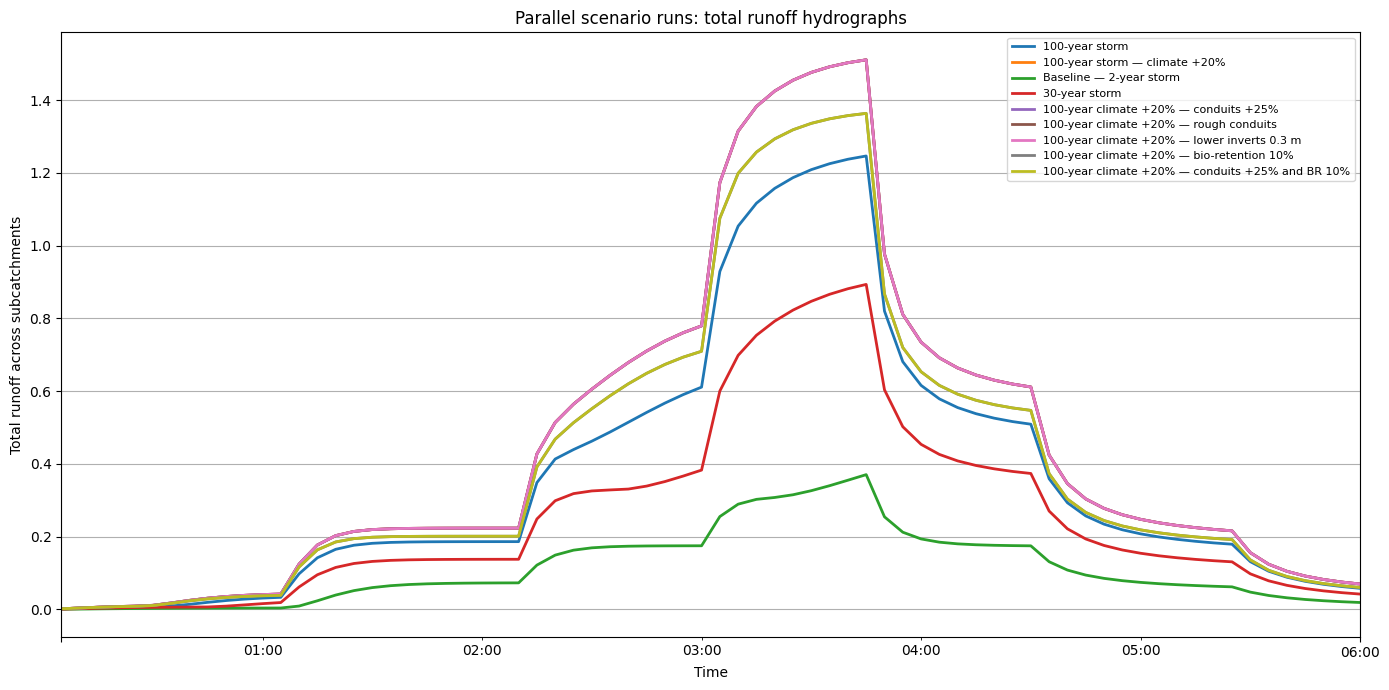

In [7]:
hydrographs = []
for row in parallel_results:
    series = pd.read_csv(row["hydrograph_csv"], index_col=0, parse_dates=True).iloc[:, 0]
    series.name = row["name"]
    hydrographs.append(series)

hydrograph_frame = pd.concat(hydrographs, axis=1)

ax = hydrograph_frame.plot(figsize=(14, 7), linewidth=2)
ax.set_title("Parallel scenario runs: total runoff hydrographs")
ax.set_xlabel("Time")
ax.set_ylabel("Total runoff across subcatchments")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()


## Plot summary metrics

These plots compare total runoff, peak runoff, maximum node depth, and maximum link flow across the scenario set.


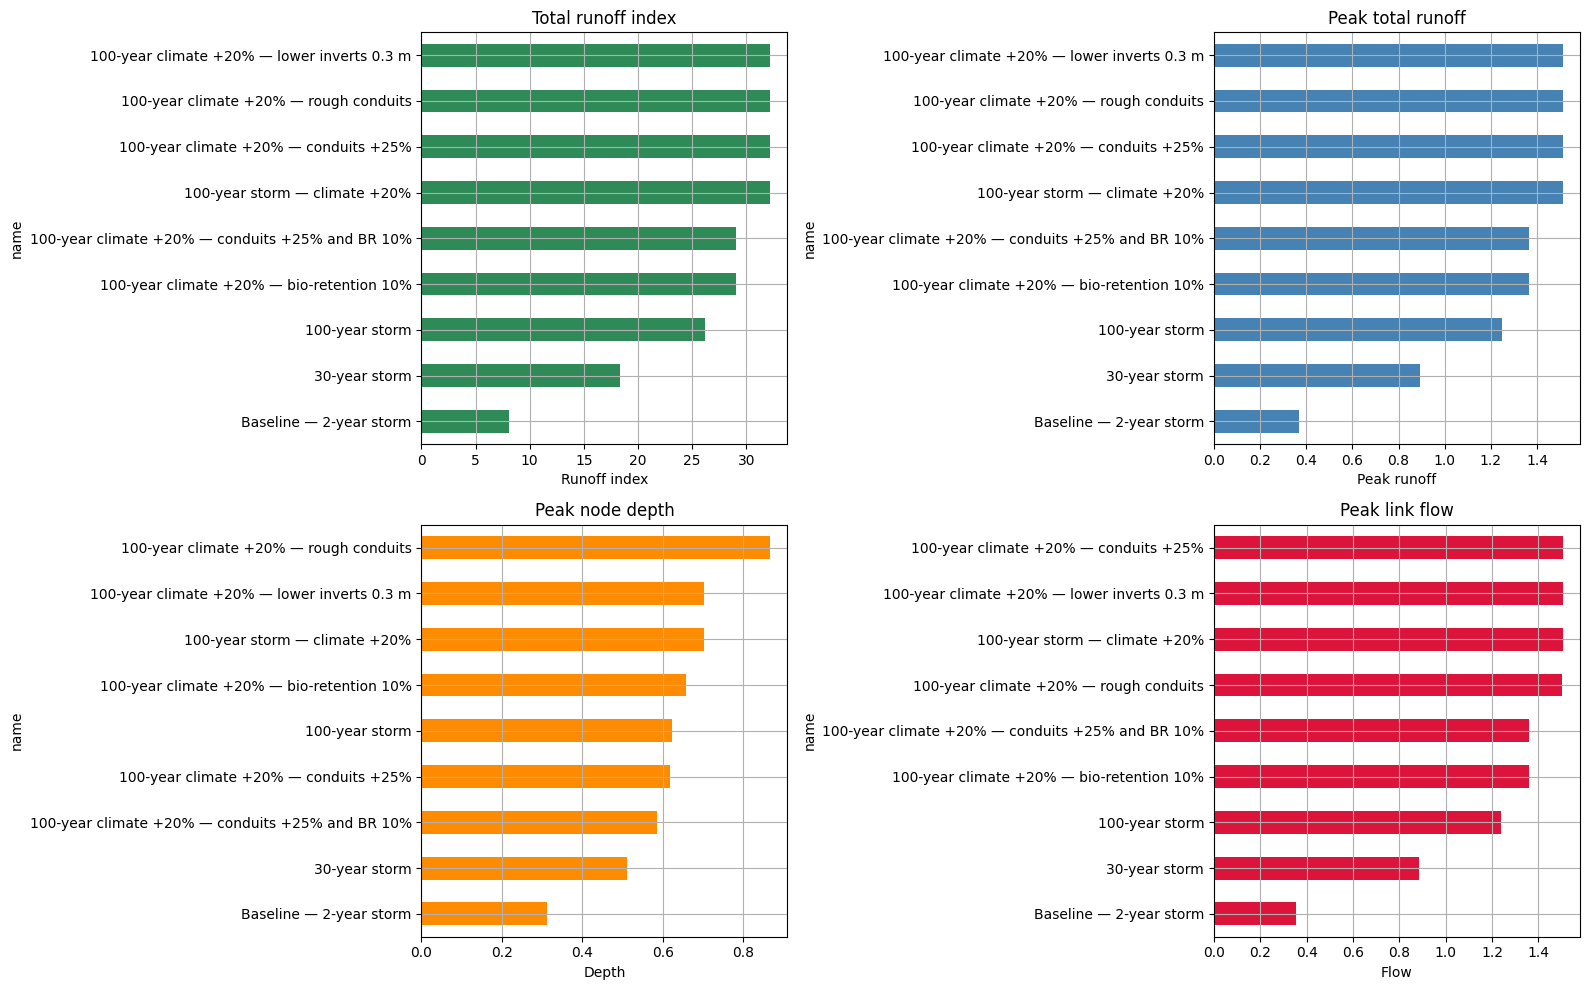

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

metrics["total_runoff_index_sum"].sort_values().plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Total runoff index")
axes[0].set_xlabel("Runoff index")

metrics["peak_total_runoff"].sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Peak total runoff")
axes[1].set_xlabel("Peak runoff")

metrics["peak_node_depth"].sort_values().plot(kind="barh", ax=axes[2], color="darkorange")
axes[2].set_title("Peak node depth")
axes[2].set_xlabel("Depth")

metrics["peak_link_flow"].sort_values().plot(kind="barh", ax=axes[3], color="crimson")
axes[3].set_title("Peak link flow")
axes[3].set_xlabel("Flow")

plt.tight_layout()


## Parallel vs serial timing template

For small teaching models, parallel overhead can be similar to model runtime. For real models with longer simulations, the speedup becomes much more meaningful. This preview times three serial worker calls as a rough comparison.


In [9]:
serial_start = time.perf_counter()
serial_preview = [run_worker(path) for path in spec_paths[:3]]
serial_elapsed = time.perf_counter() - serial_start

print(f"Serial preview: {len(serial_preview)} scenarios in {serial_elapsed:.2f} seconds")
print("For larger models, compare this with the parallel runtime above.")


Serial preview: 3 scenarios in 4.17 seconds
For larger models, compare this with the parallel runtime above.


## Practical guidance

Use parallel scenario runs when scenarios are independent, each worker creates its own `swmm()` model, and every worker writes to separate files. Avoid parallelism when workers mutate the same model object or write to the same `.inp`, `.rpt`, `.out`, or result files.

For very large studies, store scenario specs in CSV/Excel, dispatch one JSON spec per worker, and combine the resulting metrics table at the end.
